# SaaS Customer Churn Prediction — Telco Customer Churn

Capstone project: data audit, cleaning, feature engineering, model comparison, interpretability, and risk segmentation on the Telco Customer Churn dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load & Profile the Raw Data.

In [65]:
churn_data=pd.read_csv('Project_DS/WA_Fn-UseC_-Telco-Customer-Churn.csv')

`Making a copy of raw data `

In [66]:
churn_df = churn_data.copy()

`Exploring Dataset`

In [67]:
churn_df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [68]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [69]:
churn_df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [70]:
churn_df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [71]:
churn_df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [72]:
churn_df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


`Checking for missing values`

In [73]:
churn_df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Data Quality Audit

Catalog every data quality issue before changing anything.

In [74]:
missing_report = pd.DataFrame({
    'missing': churn_df.isnull().mean() * 100,
    'blank_str': (churn_df.astype(str).apply(lambda col: col.str.strip() == '').mean() * 100)
}).sort_values(by='missing', ascending=False)

print(missing_report)

                  missing  blank_str
customerID            0.0   0.000000
gender                0.0   0.000000
SeniorCitizen         0.0   0.000000
Partner               0.0   0.000000
Dependents            0.0   0.000000
tenure                0.0   0.000000
PhoneService          0.0   0.000000
MultipleLines         0.0   0.000000
InternetService       0.0   0.000000
OnlineSecurity        0.0   0.000000
OnlineBackup          0.0   0.000000
DeviceProtection      0.0   0.000000
TechSupport           0.0   0.000000
StreamingTV           0.0   0.000000
StreamingMovies       0.0   0.000000
Contract              0.0   0.000000
PaperlessBilling      0.0   0.000000
PaymentMethod         0.0   0.000000
MonthlyCharges        0.0   0.000000
TotalCharges          0.0   0.156183
Churn                 0.0   0.000000


In [75]:
# TotalCharges is stored as text, with 11 blank rows (all tenure = 0 — new, not yet billed)

print(churn_df['TotalCharges'].apply(type).value_counts())
print(churn_df[churn_df['TotalCharges'].astype(str).str.strip() == ''][['TotalCharges', 'customerID', 'tenure']])

TotalCharges
<class 'str'>    7043
Name: count, dtype: int64
     TotalCharges  customerID  tenure
488                4472-LVYGI       0
753                3115-CZMZD       0
936                5709-LVOEQ       0
1082               4367-NUYAO       0
1340               1371-DWPAZ       0
3331               7644-OMVMY       0
3826               3213-VVOLG       0
4380               2520-SGTTA       0
5218               2923-ARZLG       0
6670               4075-WKNIU       0
6754               2775-SEFEE       0


In [76]:
churn_df.groupby('Contract')['Churn'].value_counts().unstack()
churn_df.groupby(pd.cut(churn_df['tenure'], bins=[0, 6, 12, 24, 72]))['Churn'].value_counts().unstack()

C:\Users\Nelson\AppData\Local\Temp\ipykernel_18524\1730803347.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churn_df.groupby(pd.cut(churn_df['tenure'], bins=[0, 6, 12, 24, 72]))['Churn'].value_counts().unstack()


Churn,No,Yes
tenure,,
"(0, 6]",686,784
"(6, 12]",452,253
"(12, 24]",730,294
"(24, 72]",3295,538


### Exploratory churn rate by obvious candidate features

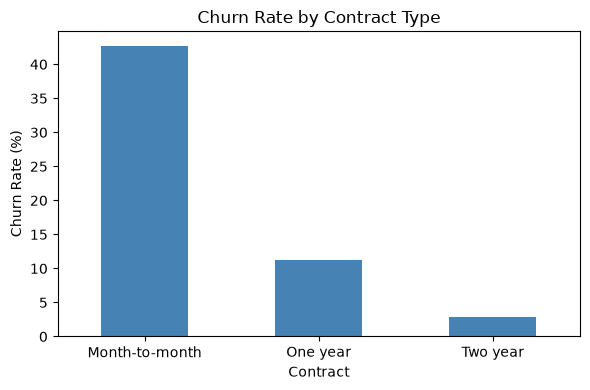

In [77]:
contract_churn = churn_df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)

plt.figure(figsize = (6, 4))
contract_churn.plot (kind='bar', color='steelblue')
plt.title ('Churn Rate by Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Contract')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

C:\Users\Nelson\AppData\Local\Temp\ipykernel_18524\258824972.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tenure_churn = churn_df.groupby('tenure_bucket')['Churn'].apply(


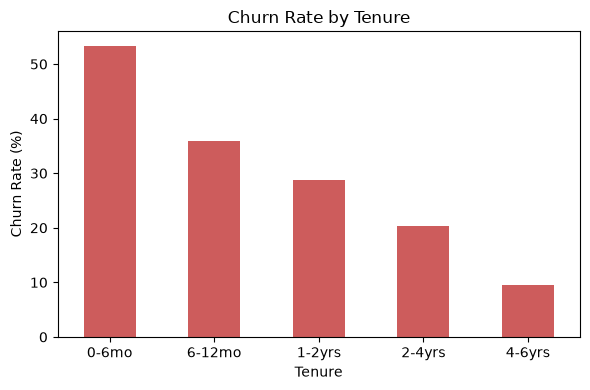

In [78]:
churn_df['tenure_bucket']= pd.cut(
    churn_df['tenure'], bins=[0, 6, 12, 24, 48, 72], labels=['0-6mo', '6-12mo', '1-2yrs', '2-4yrs', '4-6yrs']
)

tenure_churn = churn_df.groupby('tenure_bucket')['Churn'].apply(
    lambda x: (x == "Yes").mean() * 100
)

plt.figure(figsize=(6,4))
tenure_churn.plot (kind='bar', color='indianred')
plt.title ('Churn Rate by Tenure')
plt.ylabel('Churn Rate (%)')
plt.xlabel ('Tenure')
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

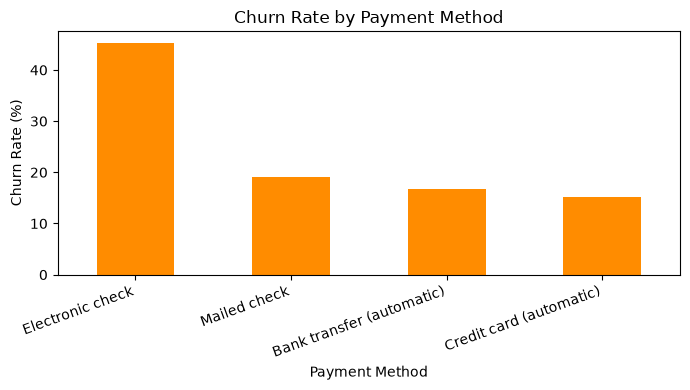

In [79]:
payment_churn= churn_df.groupby("PaymentMethod")['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(7,4))
payment_churn.plot(kind='bar', color='darkorange')
plt.title('Churn Rate by Payment Method')
plt.ylabel("Churn Rate (%)")
plt.xlabel('Payment Method')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

In [80]:
churn_df.notnull().sum()

customerID          7043
gender              7043
SeniorCitizen       7043
Partner             7043
Dependents          7043
tenure              7043
PhoneService        7043
MultipleLines       7043
InternetService     7043
OnlineSecurity      7043
OnlineBackup        7043
DeviceProtection    7043
TechSupport         7043
StreamingTV         7043
StreamingMovies     7043
Contract            7043
PaperlessBilling    7043
PaymentMethod       7043
MonthlyCharges      7043
TotalCharges        7043
Churn               7043
tenure_bucket       7032
dtype: int64

In [81]:
churn_df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges         0
Churn                0
tenure_bucket       11
dtype: int64

In [82]:
churn_df['OnlineSecurity'].unique()

array(['No', 'Yes', 'No internet service'], dtype=object)

In [83]:
churn_df['TechSupport'].unique()

array(['No', 'Yes', 'No internet service'], dtype=object)

In [84]:
churn_df['StreamingTV'].unique()

array(['No', 'Yes', 'No internet service'], dtype=object)

In [85]:
churn_df['StreamingMovies'].unique()

array(['No', 'Yes', 'No internet service'], dtype=object)

`Checks: duplicate IDs, impossible values`

In [86]:
churn_df.duplicated().sum()

np.int64(0)

In [87]:
churn_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_bucket
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-6mo
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.5,No,2-4yrs
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-6mo
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,2-4yrs
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-6mo


In [88]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7043 non-null   object  
 1   gender            7043 non-null   object  
 2   SeniorCitizen     7043 non-null   int64   
 3   Partner           7043 non-null   object  
 4   Dependents        7043 non-null   object  
 5   tenure            7043 non-null   int64   
 6   PhoneService      7043 non-null   object  
 7   MultipleLines     7043 non-null   object  
 8   InternetService   7043 non-null   object  
 9   OnlineSecurity    7043 non-null   object  
 10  OnlineBackup      7043 non-null   object  
 11  DeviceProtection  7043 non-null   object  
 12  TechSupport       7043 non-null   object  
 13  StreamingTV       7043 non-null   object  
 14  StreamingMovies   7043 non-null   object  
 15  Contract          7043 non-null   object  
 16  PaperlessBilling  7043 n

**Findings confirmed:** month-to-month contracts, low tenure, and electronic check payment all show substantially higher churn — consistent with the audit hunches above.

## Clean & Engineer Features

In [89]:
# Fix TotalCharges: blank strings (tenure=0 customers) -> 0, then convert to numeric

churn_df['TotalCharges'] = pd.to_numeric(churn_df['TotalCharges'].astype(str).str.strip().replace ('', '0'))

In [90]:
churn_df['TotalCharges'].dtype

dtype('float64')

In [91]:
# Tenure bucket as a categorical feature

churn_df['tenure_bucket'] =pd.cut(
    churn_df['tenure'],
    bins=[-1, 6, 12, 24, 48, 72],
    labels= ['0-6months', '6-12months', '1-2yrs', '2-4yrs', '4-6yrs']
)

In [92]:
churn_df['tenure_bucket'].unique()

churn_df['tenure_bucket'].value_counts()

tenure_bucket
4-6yrs        2239
2-4yrs        1594
0-6months     1481
1-2yrs        1024
6-12months     705
Name: count, dtype: int64

In [93]:
# Average monthly spend (sanity-checks TotalCharges vs tenure)

churn_df['avg_monthly_spend'] = churn_df['TotalCharges'] / churn_df['tenure'].replace(0, 1)

In [94]:
# Contract risk flag — month-to-month is the highest-churn contract type

churn_df['high_risk_contract'] = (churn_df['Contract'] == 'Month-to-month').astype(int)

In [95]:
churn_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_bucket,avg_monthly_spend,high_risk_contract
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-6months,29.850000,1
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,One year,No,Mailed check,56.95,1889.50,No,2-4yrs,55.573529,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-6months,54.075000,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,2-4yrs,40.905556,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-6months,75.825000,1


In [96]:
# Collapse "No internet/phone service" into "No" — InternetService itself preserves that distinction

service_columns = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

for col in service_columns:
    churn_df[col] = churn_df[col].replace({'No internet service': 'No'})

churn_df['MultipleLines'] = churn_df['MultipleLines'].replace({'No phone service': 'No'})



In [97]:
churn_df['MultipleLines'].unique()

array(['No', 'Yes'], dtype=object)

In [98]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   customerID          7043 non-null   object  
 1   gender              7043 non-null   object  
 2   SeniorCitizen       7043 non-null   int64   
 3   Partner             7043 non-null   object  
 4   Dependents          7043 non-null   object  
 5   tenure              7043 non-null   int64   
 6   PhoneService        7043 non-null   object  
 7   MultipleLines       7043 non-null   object  
 8   InternetService     7043 non-null   object  
 9   OnlineSecurity      7043 non-null   object  
 10  OnlineBackup        7043 non-null   object  
 11  DeviceProtection    7043 non-null   object  
 12  TechSupport         7043 non-null   object  
 13  StreamingTV         7043 non-null   object  
 14  StreamingMovies     7043 non-null   object  
 15  Contract            7043 non-null   ob

### Correlation check — before dropping redundant features

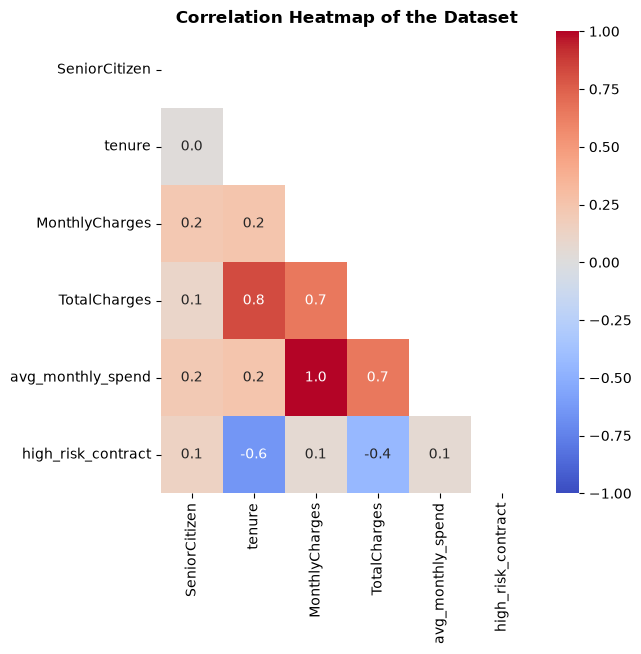

In [99]:
correlations = churn_df.corr(numeric_only=True)   
mask = np.zeros_like(correlations, dtype=np.bool)
mask[np.triu_indices_from(mask)] = True

plt.figure(figsize=(6, 6))
sns.heatmap(correlations, mask=mask, annot=True, fmt=".1f", center=0, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of the Dataset", fontweight="bold")
plt.show()

`avg_monthly_spend` is a near-duplicate of `MonthlyCharges` (r≈1.0), and `TotalCharges` itself is redundant with `tenure` and `MonthlyCharges` (r≈0.8, 0.7). Dropping both keeps `tenure` and `MonthlyCharges` as the core numeric signal without double-counting.

In [100]:
churn_df = churn_df.drop(columns = ['TotalCharges', 'avg_monthly_spend'])


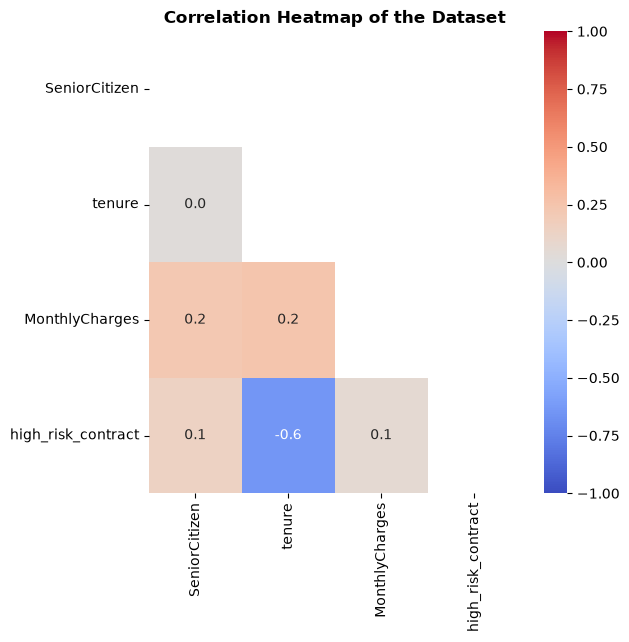

In [101]:
correlations = churn_df.corr(numeric_only=True)   
mask = np.zeros_like(correlations, dtype=np.bool)
mask[np.triu_indices_from(mask)] = True

plt.figure(figsize=(6, 6))
sns.heatmap(correlations, mask=mask, annot=True, fmt=".1f", center=0, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of the Dataset", fontweight="bold")
plt.show()


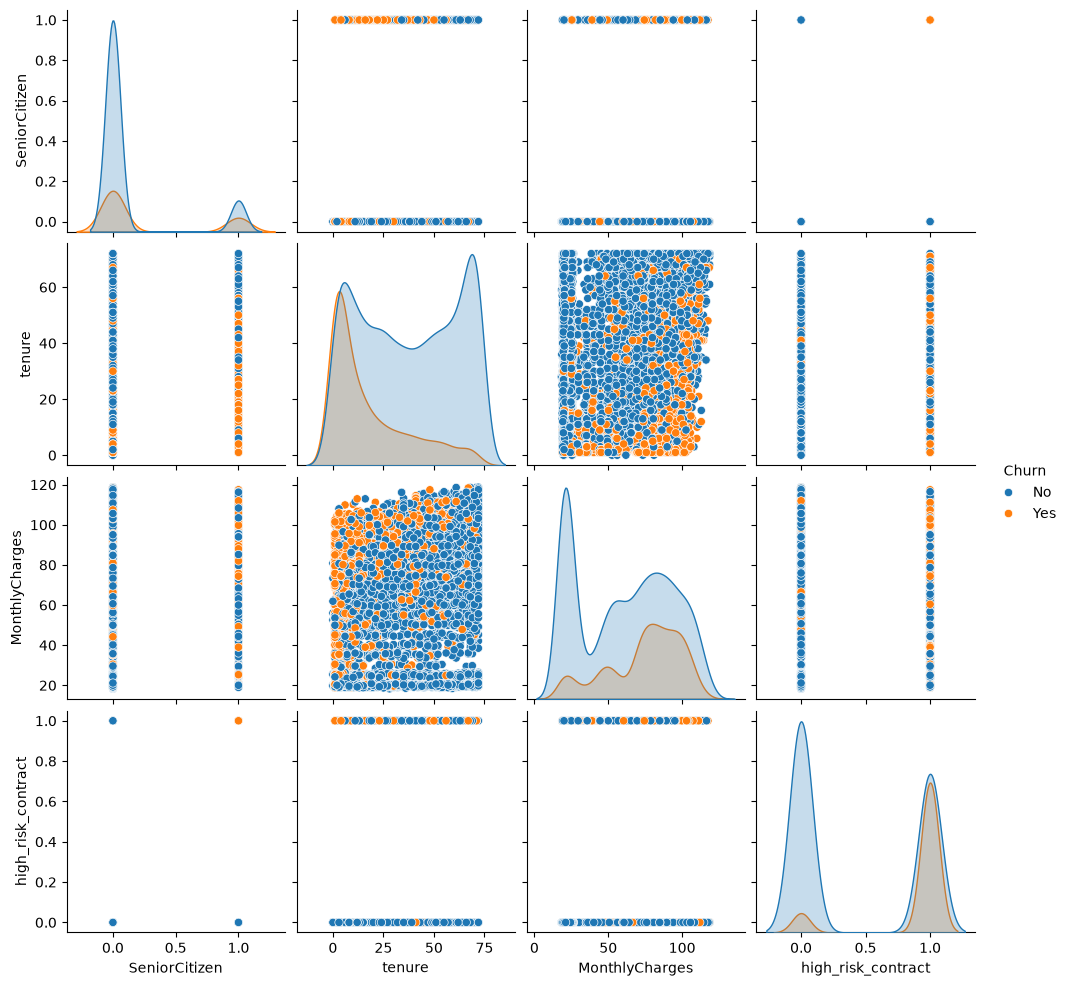

In [102]:
sns.pairplot(data=churn_df, hue="Churn")

plt.show()

## Encode Features for Modeling

In [103]:
# Keep customerID aside (not a feature), separate target

customer_ids = churn_df['customerID']
y = (churn_df['Churn'] == 'Yes').astype(int)


In [104]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()


In [105]:
# Drop columns that shouldn't go into the model

model_df = churn_df.drop(columns = ['customerID', 'Churn'])

In [106]:
categorical_cols = model_df.select_dtypes(include=['object', 'category']).columns.tolist()
print('Encoding these columns:', categorical_cols)

Encoding these columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_bucket']


In [107]:
X = pd.get_dummies(model_df, columns=categorical_cols, drop_first=True)

print('Final feature matrix shape:', X.shape)
print(X.columns.tolist())

Final feature matrix shape: (7043, 27)
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'high_risk_contract', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'tenure_bucket_6-12months', 'tenure_bucket_1-2yrs', 'tenure_bucket_2-4yrs', 'tenure_bucket_4-6yrs']


In [108]:
churn_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,Churn,tenure_bucket,high_risk_contract
0,7590-VHVEG,Female,0,Yes,No,1,No,No,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,No,0-6months,1
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,No,2-4yrs,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,Yes,0-6months,1
3,7795-CFOCW,Male,0,No,No,45,No,No,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,No,2-4yrs,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,Yes,0-6months,1


In [109]:
X.shape

(7043, 27)

In [110]:
X.columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'high_risk_contract',
       'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes',
       'MultipleLines_Yes', 'InternetService_Fiber optic',
       'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes',
       'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes',
       'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year',
       'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check',
       'tenure_bucket_6-12months', 'tenure_bucket_1-2yrs',
       'tenure_bucket_2-4yrs', 'tenure_bucket_4-6yrs'],
      dtype='object')

## Finalize the Clean Dataset

**Data cleaning log**
- `TotalCharges`: 11 rows had blank strings, all with `tenure = 0` (new customers, not yet billed). Converted to numeric, blanks filled as 0.
- Collapsed `"No internet service"` / `"No phone service"` into `"No"` across 7 service columns — `InternetService` itself still preserves that distinction.
- Engineered `tenure_bucket`, `avg_monthly_spend`, `high_risk_contract` as candidate features.
- Correlation check showed `avg_monthly_spend` (r=1.0 with `TotalCharges`) and `TotalCharges` (r=0.8/0.7 with `tenure`/`MonthlyCharges`) were redundant — both dropped.
- No duplicate `customerID`s, no negative tenure/charges found.
- One-hot encoded remaining categoricals with `drop_first=True`. Final shape: (7043, 27).
- **Class-imbalance strategy:** class weighting (`class_weight='balanced'`) chosen over SMOTE — adjusts the loss function without fabricating synthetic customer records, keeping the decision boundary grounded in real observed data.

` Save Cleaned Data`

In [111]:
# Save the cleaned, feature-engineered dataset — separate from raw
import os
os.makedirs('Project_DS/data', exist_ok=True)
churn_df.to_csv('Project_DS/data/telco_churn_cleaned.csv', index=False)
print("Saved:", churn_df.shape)


Saved: (7043, 22)


## Train/Test Split & Model Comparison

Accuracy is excluded as a decision metric: with ~26% churn, a model that always predicts "no churn" scores ~74% accuracy while being useless. Recall, precision, F1, and ROC-AUC are used instead.

In [112]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [113]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print('Train shape:', X_train.shape, "Test shape:", X_test.shape)
print('Train churn rate', y_train.mean(), "Test churn rate:", y_test.mean())

Train shape: (5634, 27) Test shape: (1409, 27)
Train churn rate 0.2653532126375577 Test churn rate: 0.2654364797728886


### Model 1 — Logistic Regression

In [114]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [115]:
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [116]:
print ("Train accuracy:", model.score(X_train_scaled, y_train))
print ("Test accuracy:", model.score(X_test_scaled, y_test))

Train accuracy: 0.7561235356762513
Test accuracy: 0.7395315826827538


Classification Report: 

              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Confusion Matrix:
[[742 293]
 [ 74 300]]
ROC AUC Score:
0.844656281484926


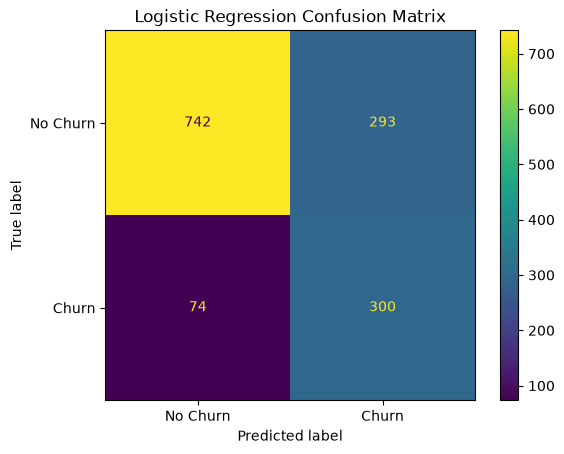

In [117]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay

y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

print("Classification Report: \n")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("ROC AUC Score:")
print(roc_auc_score(y_test, y_pred_proba))

cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
display.plot()
plt.title ('Logistic Regression Confusion Matrix')
plt.show()

In [118]:
# Logistic Regression WITHOUT imbalance handling — same split, same features
log_reg_unweighted = LogisticRegression(max_iter=1000, random_state=42)
log_reg_unweighted.fit(X_train_scaled, y_train)

y_pred_uw = log_reg_unweighted.predict(X_test_scaled)
y_pred_proba_uw = log_reg_unweighted.predict_proba(X_test_scaled)[:, 1]

print("Unweighted Logistic Regression:\n")
print(classification_report(y_test, y_pred_uw, target_names=['No Churn', 'Churn']))
print("ROC-AUC:", roc_auc_score(y_test, y_pred_proba_uw))

Unweighted Logistic Regression:

              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.66      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409

ROC-AUC: 0.8445167790436333


### Model 2 — Random Forest

Random Forest Classification Report: 

              precision    recall  f1-score   support

    No Churn       0.91      0.70      0.79      1035
       Churn       0.49      0.80      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.74      1409


Random Forest Confusion Matrix:
[[724 311]
 [ 73 301]]
Random Forest ROC AUC Score:
0.8209305329509934


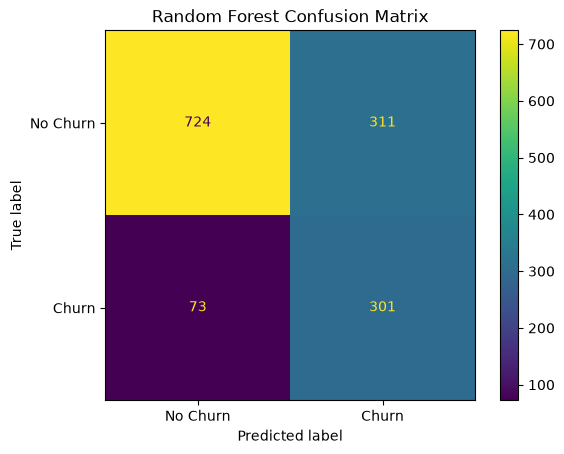

In [119]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay

rf_clf = RandomForestClassifier(
    class_weight='balanced', 
    n_estimators=200, 
    n_jobs=-1, 
    random_state=42
)
rf_clf.fit(X_train, y_train)

y_pred_rf = rf_clf.predict(X_test)
y_pred_proba_rf = rf_clf.predict_proba(X_test)[:, 1]

custom_threshold = 0.35
y_pred_rf_custom = (y_pred_proba_rf >= custom_threshold).astype(int)

print("Random Forest Classification Report: \n")
print(classification_report(y_test, y_pred_rf_custom, target_names=['No Churn', 'Churn']))

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_custom))

print("Random Forest ROC AUC Score:")
print(roc_auc_score(y_test, y_pred_proba_rf))

cm = confusion_matrix(y_test, y_pred_rf_custom)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
display.plot()
plt.title ('Random Forest Confusion Matrix')
plt.show()

### Model 3 — XGBoost

scale_pos_weight: 2.768561872909699
XGBoost Classification Report (default threshold 0.5):

              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.81      1035
       Churn       0.52      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.75      0.76      1409


Confusion Matrix:
[[772 263]
 [ 89 285]]

ROC-AUC Score: 0.8348936939729779


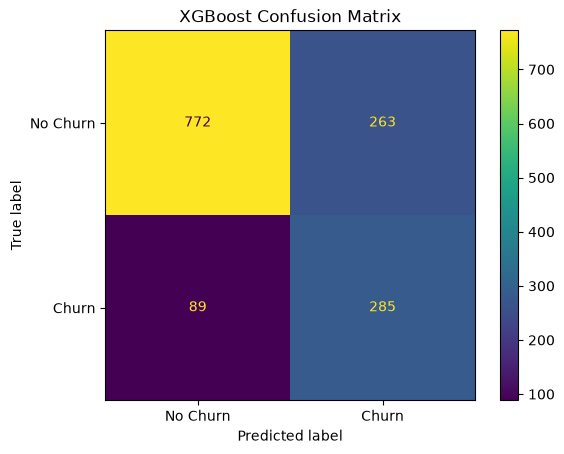

In [120]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay

# scale_pos_weight = (negative class count) / (positive class count)
# This is XGBoost's version of class_weight='balanced'
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", scale_pos_weight)

xgb_clf = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
)
xgb_clf.fit(X_train, y_train)

y_pred_proba_xgb = xgb_clf.predict_proba(X_test)[:, 1]
y_pred_xgb = xgb_clf.predict(X_test)

print("XGBoost Classification Report (default threshold 0.5):\n")
print(classification_report(y_test, y_pred_xgb, target_names=['No Churn', 'Churn']))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nROC-AUC Score:", roc_auc_score(y_test, y_pred_proba_xgb))

cm = confusion_matrix(y_test, y_pred_xgb)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
display.plot()
plt.title ('XGBoost Confusion Matrix')
plt.show()

### Model comparison summary

| Model | Churn Recall | Churn Precision | Churn F1 | ROC-AUC |
|---|---|---|---|---|
| Logistic Regression | 0.80 | 0.51 | 0.62 | **0.845** |
| Random Forest (threshold 0.35) | 0.80 | 0.49 | 0.61 | 0.821 |
| XGBoost (default) | 0.76 | 0.52 | 0.62 | 0.835 |

**Logistic Regression selected as the final model** — highest ROC-AUC (threshold-independent), and matches or beats the tree-based models on F1 at equal recall. Added model complexity did not outperform a simple linear model on this dataset.

## Interpretability

Coefficients from the final Logistic Regression model (fit on standardized features, so magnitudes are directly comparable).

In [121]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)

# Find the threshold closest to your chosen operating point
target_recall = 0.75
idx = np.argmin(np.abs(recalls - target_recall))
print(f"To hit ~{target_recall} recall: threshold ≈ {thresholds[idx]:.2f}, "
      f"precision ≈ {precisions[idx]:.2f}")

To hit ~0.75 recall: threshold ≈ 0.56, precision ≈ 0.54


In [122]:
error_df = X_test.copy()
error_df['actual'] = y_test.values
error_df['predicted'] = y_pred
error_df['churn_probability']= y_pred_proba

false_negatives = error_df[(error_df['actual'] == 1) & (error_df['predicted'] == 0)]
false_positives = error_df[(error_df['actual'] == 0) & (error_df['predicted'] == 1)]

print ("False Negatives (missed churners):", len(false_negatives))
print(false_negatives[['tenure', 'MonthlyCharges', 'high_risk_contract', 'churn_probability']].describe())


print ("\nFalse Positives (flagged, but stayed):", len(false_positives))
print(false_positives[['tenure', 'MonthlyCharges', 'high_risk_contract', 'churn_probability']].describe())

False Negatives (missed churners): 74
          tenure  MonthlyCharges  high_risk_contract  churn_probability
count  74.000000       74.000000           74.000000          74.000000
mean   31.445946       62.432432            0.500000           0.322138
std    22.845606       31.858003            0.503413           0.124761
min     1.000000       18.950000            0.000000           0.020595
25%    10.250000       25.487500            0.000000           0.220814
50%    31.000000       60.125000            0.500000           0.349491
75%    52.000000       93.687500            1.000000           0.422113
max    72.000000      115.650000            1.000000           0.494430

False Positives (flagged, but stayed): 293
           tenure  MonthlyCharges  high_risk_contract  churn_probability
count  293.000000      293.000000          293.000000         293.000000
mean    21.535836       76.966724            0.907850           0.688026
std     19.027816       22.123387            0.2897

In [123]:


# Get coefficients paired with feature names
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model.coef_[0]
})

# Sort by absolute value — magnitude matters more than sign for "importance"
feature_importance['abs_coefficient'] = feature_importance['coefficient'].abs()
feature_importance = feature_importance.sort_values('abs_coefficient', ascending=False)

print(feature_importance.head(10))

                        feature  coefficient  abs_coefficient
2                MonthlyCharges    -0.879649         0.879649
9   InternetService_Fiber optic     0.816376         0.816376
10           InternetService_No    -0.646734         0.646734
1                        tenure    -0.577552         0.577552
18            Contract_Two year    -0.394807         0.394807
3            high_risk_contract     0.350318         0.350318
25         tenure_bucket_2-4yrs    -0.350069         0.350069
16          StreamingMovies_Yes     0.298612         0.298612
24         tenure_bucket_1-2yrs    -0.288172         0.288172
15              StreamingTV_Yes     0.285908         0.285908


**Top churn drivers:** fiber optic internet service is the single strongest risk signal, followed by monthly charges (entangled with fiber service and no internet service. Tenure and two-year contracts confirm the exploratory findings.

## Risk Segmentation & Business Recommendations

In [124]:
# Get churn probabilities for the full test set
risk_df = X_test.copy()
risk_df['churn_probability'] = model.predict_proba(X_test_scaled)[:, 1]
risk_df['actual_churn'] = y_test.values

# Define risk tiers
def assign_tier(prob):
    if prob >= 0.6:
        return 'High Risk'
    elif prob >= 0.3:
        return 'Medium Risk'
    else:
        return 'Low Risk'

risk_df['risk_tier'] = risk_df['churn_probability'].apply(assign_tier)

# How many customers land in each tier, and what's the actual churn rate within each?
tier_summary = risk_df.groupby('risk_tier').agg(
    customer_count=('actual_churn', 'count'),
    actual_churn_rate=('actual_churn', 'mean'),
    avg_predicted_prob=('churn_probability', 'mean')
)
print(tier_summary)

             customer_count  actual_churn_rate  avg_predicted_prob
risk_tier                                                         
High Risk               473           0.558140            0.778317
Low Risk                611           0.045827            0.112403
Medium Risk             325           0.252308            0.452562


**Business takeaway:** High Risk customers churn at 55.8% vs. 4.6% for Low Risk — a 12x difference. Retention spend should concentrate on the High Risk tier (proactive outreach, targeted offers), use low-cost automated nudges for Medium Risk, and leave Low Risk customers unaddressed to avoid wasted spend.

**Limitations:** predicted probabilities run higher than actual churn rates within each tier (a side effect of class weighting) — tier *ranking* is valid, but raw probabilities would need calibration before being read as literal likelihoods. This dataset is also a single point-in-time snapshot, not a longitudinal record.

`## Save Model`

In [125]:
import joblib


joblib.dump(model, 'Telco_Customer_Churn.joblib')
joblib.dump(rf_clf, 'Telco_Customer_Churn.joblib')
joblib.dump(xgb_clf, 'Telco_Customer_Churn.joblib')

joblib.dump(scaler, 'scaler.joblib')

print("Model and scaler saved successfully.")

Model and scaler saved successfully.


In [126]:
import joblib, sklearn, pandas
print(sklearn.__version__, pandas.__version__)

1.9.0 2.3.3


In [150]:
old_model_df = model_df.copy()

In [151]:
import pandas as pd
from features import prepare_features

raw = pd.read_csv("Project_DS/WA_Fn-UseC_-Telco-Customer-Churn.csv")   # your file name
model_df = prepare_features(raw)
y = (raw["Churn"] == "Yes").astype(int)

print((old_model_df.astype(str).values == model_df.astype(str).values).all())

True


In [152]:
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

categorical_cols = model_df.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in model_df.columns if c not in categorical_cols]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    model_df, y, test_size=0.2, stratify=y, random_state=42)

pipe = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols),
        ("num", StandardScaler(), num_cols),
    ])),
    ("model", LogisticRegression(class_weight="balanced",
                                 max_iter=1000, random_state=42)),
])
pipe.fit(X_train_raw, y_train)

print("ROC-AUC:", roc_auc_score(y_test, pipe.predict_proba(X_test_raw)[:, 1]))
print("Class order:", pipe.classes_)          # [0 1] means column 1 = churn
print("Sample customer:", pipe.predict_proba(X_test_raw.iloc[[0]]))

joblib.dump(pipe, "model/churn_model.joblib")

ROC-AUC: 0.8450050375881577
Class order: [0 1]
Sample customer: [[0.89257362 0.10742638]]


['model/churn_model.joblib']

In [172]:
import joblib, pandas as pd
from sklearn.model_selection import train_test_split
from features import prepare_features

pipe = joblib.load("model/churn_model.joblib")
raw = pd.read_csv("Project_DS/WA_Fn-UseC_-Telco-Customer-Churn.csv")
model_df = prepare_features(raw)
y = (raw["Churn"] == "Yes").astype(int)

_, X_test_raw, _, _ = train_test_split(model_df, y, test_size=0.2, stratify=y, random_state=42)
idx = X_test_raw.index[0]
print(pipe.predict_proba(prepare_features(raw.loc[[idx]])))

[[0.89257362 0.10742638]]


In [173]:
for c in ["gender","Partner","Dependents","PhoneService","MultipleLines","InternetService",
          "OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
          "StreamingMovies","Contract","PaperlessBilling","PaymentMethod"]:
    print(c, sorted(raw[c].unique()))
print(raw["MonthlyCharges"].min(), raw["MonthlyCharges"].max(), raw["tenure"].min(), raw["tenure"].max())

gender ['Female', 'Male']
Partner ['No', 'Yes']
Dependents ['No', 'Yes']
PhoneService ['No', 'Yes']
MultipleLines ['No', 'No phone service', 'Yes']
InternetService ['DSL', 'Fiber optic', 'No']
OnlineSecurity ['No', 'No internet service', 'Yes']
OnlineBackup ['No', 'No internet service', 'Yes']
DeviceProtection ['No', 'No internet service', 'Yes']
TechSupport ['No', 'No internet service', 'Yes']
StreamingTV ['No', 'No internet service', 'Yes']
StreamingMovies ['No', 'No internet service', 'Yes']
Contract ['Month-to-month', 'One year', 'Two year']
PaperlessBilling ['No', 'Yes']
PaymentMethod ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
18.25 118.75 0 72


In [174]:
print(raw.iloc[0].to_dict())
print(pipe.predict_proba(prepare_features(raw.iloc[[0]]))[0, 1])

{'customerID': '7590-VHVEG', 'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'Yes', 'Dependents': 'No', 'tenure': 1, 'PhoneService': 'No', 'MultipleLines': 'No phone service', 'InternetService': 'DSL', 'OnlineSecurity': 'No', 'OnlineBackup': 'Yes', 'DeviceProtection': 'No', 'TechSupport': 'No', 'StreamingTV': 'No', 'StreamingMovies': 'No', 'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes', 'PaymentMethod': 'Electronic check', 'MonthlyCharges': 29.85, 'TotalCharges': '29.85', 'Churn': 'No'}
0.8229639521302718


In [175]:
print(pipe.predict_proba(prepare_features(raw.iloc[[0]]))[0, 1])

0.8229639521302718


In [176]:
import sklearn, pandas, joblib
print(sklearn.__version__, pandas.__version__, joblib.__version__)

1.9.0 2.3.3 1.6.0


## Time Based Split

In [177]:
import numpy as np, pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             roc_auc_score, average_precision_score)

THRESHOLD = 0.6   # use the same threshold as your original results table

def make_pipe(cat_cols, num_cols, C=1.0):
    return Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
            ("num", StandardScaler(), num_cols),
        ])),
        ("model", LogisticRegression(class_weight="balanced", C=C,
                                     max_iter=1000, random_state=42)),
    ])

def evaluate(fitted_pipe, X, y_true, threshold=THRESHOLD):
    p = fitted_pipe.predict_proba(X)[:, 1]
    pred = (p >= threshold).astype(int)
    return {"Recall": recall_score(y_true, pred),
            "Precision": precision_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, p),
            "PR-AUC": average_precision_score(y_true, p)}

In [178]:
cutoff = int(np.percentile(model_df["tenure"], 25))
is_train = model_df["tenure"] > cutoff      # longer tenure = joined earlier = "the past"
X_tr, y_tr = model_df[is_train], y[is_train]
X_te, y_te = model_df[~is_train], y[~is_train]

order = X_tr["tenure"].sort_values(ascending=False, kind="stable").index
X_tr, y_tr = X_tr.loc[order], y_tr.loc[order]   # earliest -> latest, for forward-chaining CV

print("train = tenure >", cutoff, "months")
print("train:", len(X_tr), "rows | churn rate", round(y_tr.mean(), 3))
print("test :", len(X_te), "rows | churn rate", round(y_te.mean(), 3))
print("train tenure range:", X_tr["tenure"].min(), "-", X_tr["tenure"].max())
print("test  tenure range:", X_te["tenure"].min(), "-", X_te["tenure"].max())

train = tenure > 9 months
train: 5189 rows | churn rate 0.182
test : 1854 rows | churn rate 0.498
train tenure range: 10 - 72
test  tenure range: 0 - 9


In [179]:
pipe_time = make_pipe(categorical_cols, num_cols).fit(X_tr, y_tr)

grid = GridSearchCV(make_pipe(categorical_cols, num_cols),
                    param_grid={"model__C": [0.01, 0.1, 1, 10]},
                    cv=TimeSeriesSplit(n_splits=4),
                    scoring="average_precision")
grid.fit(X_tr, y_tr)
print("best settings:", grid.best_params_)

c:\Users\Nelson\Documents\GitHub\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Nelson\Documents\GitHub\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Nelson\Documents\GitHub\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Nelson\Documents\GitHub\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [15] during transform. These unknown categories will be encoded as all zeros
  warn

best settings: {'model__C': 0.01}


c:\Users\Nelson\Documents\GitHub\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Nelson\Documents\GitHub\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Nelson\Documents\GitHub\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [180]:
results = pd.DataFrame({
    "Random split (original)": evaluate(pipe, X_test_raw, y_test),
    "Time split, same settings": evaluate(pipe_time, X_te, y_te),
    "Time split, tuned (forward-chaining CV)": evaluate(grid.best_estimator_, X_te, y_te),
}).T.round(3)
results

c:\Users\Nelson\Documents\GitHub\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Nelson\Documents\GitHub\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Recall,Precision,F1,ROC-AUC,PR-AUC
Random split (original),0.703,0.557,0.622,0.845,0.651
"Time split, same settings",0.774,0.662,0.713,0.756,0.732
"Time split, tuned (forward-chaining CV)",0.777,0.659,0.713,0.756,0.731


In [181]:
drop = ["tenure", "tenure_bucket"]
cat2 = [c for c in categorical_cols if c not in drop]
num2 = [c for c in num_cols if c not in drop]
pipe_a = make_pipe(cat2, num2).fit(X_train_raw.drop(columns=drop), y_train)
pipe_b = make_pipe(cat2, num2).fit(X_tr.drop(columns=drop), y_tr)
extra = pd.DataFrame({
    "Random split, no tenure features": evaluate(pipe_a, X_test_raw.drop(columns=drop), y_test),
    "Time split, no tenure features": evaluate(pipe_b, X_te.drop(columns=drop), y_te),
}).T.round(3)
extra

,Recall,Precision,F1,ROC-AUC,PR-AUC
"Random split, no tenure features",0.698,0.523,0.598,0.818,0.571
"Time split, no tenure features",0.705,0.693,0.699,0.760,0.735


## Monitoring Check

In [182]:
train_scores = pipe.predict_proba(X_train_raw)[:, 1]
baseline = {
    "threshold": THRESHOLD,
    "churn_rate": float(y_train.mean()),
    "mean_score": float(train_scores.mean()),
    "flag_rate": float((train_scores >= THRESHOLD).mean()),
    "scores": train_scores,
}
print({k: round(v, 3) for k, v in baseline.items() if k != "scores"})

{'threshold': 0.6, 'churn_rate': 0.265, 'mean_score': 0.412, 'flag_rate': 0.327}


In [183]:
from features import prepare_features

def psi(base_scores, new_scores, bins=10):
    edges = np.quantile(base_scores, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    b = np.histogram(base_scores, edges)[0] / len(base_scores)
    n = np.histogram(new_scores, edges)[0] / len(new_scores)
    b, n = np.clip(b, 1e-4, None), np.clip(n, 1e-4, None)
    return float(np.sum((n - b) * np.log(n / b)))

def check_batch(raw_batch, model=pipe, base=baseline, min_n=100):
    n = len(raw_batch)
    if n < min_n:
        return {"status": "TOO SMALL",
                "message": f"TOO SMALL: {n} rows is below the minimum of {min_n}; cannot judge drift."}
    scores = model.predict_proba(prepare_features(raw_batch))[:, 1]
    flag_rate = float((scores >= base["threshold"]).mean())
    se = np.sqrt(base["flag_rate"] * (1 - base["flag_rate"]) / n)
    z = (flag_rate - base["flag_rate"]) / se
    p = psi(base["scores"], scores)

    def level(value, warn, alert):
        return "ALERT" if abs(value) >= alert else "WARNING" if abs(value) >= warn else "OK"
    rank = {"OK": 0, "WARNING": 1, "ALERT": 2}
    status = max(level(z, 2, 3), level(p, 0.10, 0.25), key=rank.get)

    msg = (f"{status}: flagged {flag_rate:.1%} vs baseline {base['flag_rate']:.1%} "
           f"(z = {z:+.1f}); score PSI = {p:.3f}; "
           f"mean score {scores.mean():.3f} vs {base['mean_score']:.3f}; n = {n}")
    return {"status": status, "message": msg, "flag_rate": flag_rate, "z": z, "psi": p}

In [184]:
raw_test = raw.loc[X_test_raw.index]          # original-format rows of the held-out customers

normal = raw_test.sample(500, random_state=1)
print(check_batch(normal)["message"])

mtm = raw_test[raw_test["Contract"] == "Month-to-month"]
other = raw_test[raw_test["Contract"] != "Month-to-month"]
drifted = pd.concat([mtm.sample(425, replace=True, random_state=1),
                     other.sample(75, replace=True, random_state=1)])
print(check_batch(drifted)["message"])

short = raw_test.sample(500, random_state=2).copy()
short["tenure"] = short["tenure"].clip(upper=6)
print(check_batch(short)["message"])

print(check_batch(raw_test.head(40))["message"])

OK: flagged 34.4% vs baseline 32.7% (z = +0.8); score PSI = 0.023; mean score 0.410 vs 0.412; n = 500
ALERT: flagged 54.6% vs baseline 32.7% (z = +10.4); score PSI = 0.352; mean score 0.573 vs 0.412; n = 500
ALERT: flagged 54.8% vs baseline 32.7% (z = +10.5); score PSI = 1.589; mean score 0.610 vs 0.412; n = 500
TOO SMALL: 40 rows is below the minimum of 100; cannot judge drift.


In [185]:
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test

surv = raw.loc[model_df.index].copy()
surv["duration"] = surv["tenure"].clip(lower=1)   # months; avoids zero-length durations
surv["event"] = y.loc[surv.index].astype(int)     # 1 = churned, 0 = still a customer (censored)
print(surv[["duration", "event"]].describe().round(2))

       duration    event
count   7043.00  7043.00
mean      32.37     0.27
std       24.56     0.44
min        1.00     0.00
25%        9.00     0.00
50%       29.00     0.00
75%       55.00     1.00
max       72.00     1.00


Month-to-month | still a customer at 12 months: 0.703 | at 24 months: 0.586
One year | still a customer at 12 months: 0.991 | at 24 months: 0.978
Two year | still a customer at 12 months: 1.0 | at 24 months: 1.0


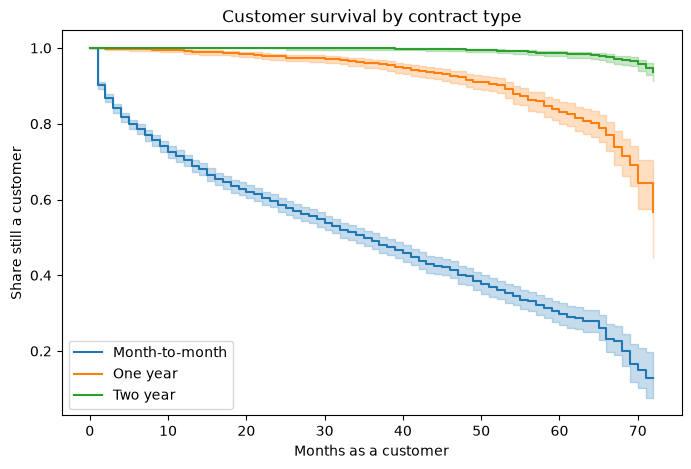

In [191]:
kmf = KaplanMeierFitter()
fig, ax = plt.subplots(figsize=(8, 5))
for name, grp in surv.groupby("Contract"):
    kmf.fit(grp["duration"], grp["event"], label=name)
    kmf.plot_survival_function(ax=ax, ci_show=True)
    print(name, "| still a customer at 12 months:", round(float(kmf.predict(12)), 3),
          "| at 24 months:", round(float(kmf.predict(24)), 3))
ax.set_xlabel("Months as a customer")
ax.set_ylabel("Share still a customer")
ax.set_title("Customer survival by contract type")
import os; os.makedirs("images", exist_ok=True)
plt.savefig("images/km_by_contract.png", dpi=150, bbox_inches="tight")   # use hazard_ratios.png for the second plot
plt.show()

In [192]:
a = surv[surv["Contract"] == "Month-to-month"]
b = surv[surv["Contract"] == "Two year"]
res = logrank_test(a["duration"], b["duration"], a["event"], b["event"])
print("log-rank p-value:", res.p_value)

log-rank p-value: 0.0


<lifelines.CoxPHFitter: fitted with 5634 total observations, 4139 right-censored observations>
             duration col = 'duration'
                event col = 'event'
                penalizer = 0.01
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 5634
number of events observed = 1495
   partial log-likelihood = -10908.27
         time fit was run = 2026-10-28 08:41:33 UTC

---
                                       coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                              
SeniorCitizen                         -0.12      0.89      0.06           -0.24            0.00                0.79                1.00
MonthlyCharges                        -0.02      0.98      0.00           -0.02           -0.01                0.98                0.99
Contract_One year                     -1.53      0.22      0.09           -1.71           -1.36                0.18                0.26
Contract_Two year                     -2.57      0.08      0.13           -2.83           -2.31                0.06                0.10
InternetService_Fiber optic            0.83      2.29      0.10            0.63            1.03                1.87                2.79
InternetService_No                    -0.41      0.66      0.27           -0.94            0.11                0.39                1.12
PaymentMethod_Credit card (automatic) -0.12      0.89      0.09           -0.30            0.07                0.74                1.07
PaymentMethod_Electronic check         0.61      1.84      0.07            0.47            0.75                1.59                2.12
PaymentMethod_Mailed check             0.66      1.93      0.09            0.48            0.84                1.61                2.31
PaperlessBilling_Yes                   0.16      1.17      0.06            0.04            0.28                1.04                1.32
Partner_Yes                           -0.51      0.60      0.06           -0.63           -0.40                0.53                0.67
Dependents_Yes                        -0.12      0.88      0.07           -0.27            0.02                0.77                1.02
TechSupport_No internet service       -0.41      0.66      0.27           -0.94            0.11                0.39                1.12
TechSupport_Yes                       -0.38      0.69      0.07           -0.52           -0.23                0.60                0.79
OnlineSecurity_No internet service    -0.41      0.66      0.27           -0.94            0.11                0.39                1.12
OnlineSecurity_Yes                    -0.59      0.56      0.07           -0.73           -0.45                0.48                0.64

                                       cmp to      z      p  -log2(p)
covariate                                                            
SeniorCitizen                            0.00  -1.95   0.05      4.30
MonthlyCharges                           0.00  -7.94 <0.005     48.79
Contract_One year                        0.00 -17.03 <0.005    213.71
Contract_Two year                        0.00 -19.34 <0.005    274.51
InternetService_Fiber optic              0.00   8.15 <0.005     51.24
InternetService_No                       0.00  -1.55   0.12      3.04
PaymentMethod_Credit card (automatic)    0.00  -1.23   0.22      2.21
PaymentMethod_Electronic check           0.00   8.31 <0.005     53.18
PaymentMethod_Mailed check               0.00   7.13 <0.005     39.81
PaperlessBilling_Yes                     0.00   2.54   0.01      6.49
Partner_Yes                              0.00  -8.66 <0.005     57.54
Dependents_Yes                           0.00  -1.65   0.10      3.34
TechSupport_No internet service          0.00  -1.55   0.12      3.04
TechSupport_Yes                          0.00  -5.21 <0.005     22.36

Concordance, train: 0.858
Concordance, test : 0.845


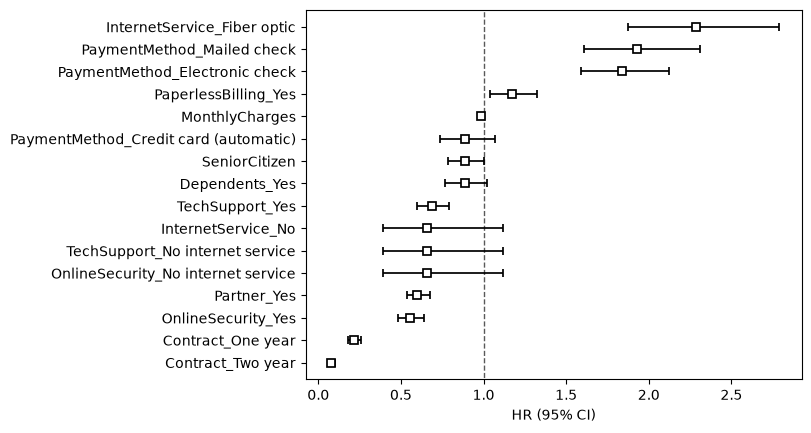

In [193]:
cox_cols = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling",
            "SeniorCitizen", "Partner", "Dependents", "TechSupport", "OnlineSecurity",
            "MonthlyCharges"]
cox_df = pd.get_dummies(surv[cox_cols], drop_first=True, dtype=float)
cox_df["duration"] = surv["duration"]
cox_df["event"] = surv["event"]

train_c = cox_df.loc[X_train_raw.index]     # same train/test split as before
test_c = cox_df.loc[X_test_raw.index]

cph = CoxPHFitter(penalizer=0.01)
cph.fit(train_c, duration_col="duration", event_col="event")
cph.print_summary(decimals=2)

print("Concordance, train:", round(cph.concordance_index_, 3))
print("Concordance, test :", round(cph.score(test_c, scoring_method="concordance_index"), 3))

cph.plot(hazard_ratios=True)
plt.show()

In [194]:
cph.check_assumptions(train_c, p_value_threshold=0.01, show_plots=False)

The ``p_value_threshold`` is set at 0.01. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'MonthlyCharges' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'MonthlyCharges' might be incorrect. That is, there
may be non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'MonthlyCharges' using pd.cut, and then specify it in
`strata=['MonthlyCharges', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'Contract_One year' failed the non-proportional test: p-value is <5e-05.

   Advice: with so few unique values (only 2), you can include `strata=['Contract_One year', ...]`
in the call in `.fit`. See documentation in link [E] below.

3. Variable 'PaymentMethod_Mailed check' failed the non-proportional test: p-value i

[]

In [195]:
sample = test_c.drop(columns=["duration", "event"]).iloc[:3]
sf = cph.predict_survival_function(sample, times=[6, 12, 24])
print(sf.round(3))

       437    2280   2235
6.0   0.998  0.903  0.993
12.0  0.997  0.853  0.990
24.0  0.995  0.776  0.983
